# Import necessary library

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('retail_store_sales.csv')

# Check duplicated row

In [4]:
print(df.duplicated().sum())

0


# Backup df to start cleanning

In [5]:
df_clean = df.copy()

In [6]:
print(df_clean.columns)

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')


# Process Cleanning

## Check duplicated and missing value in ID columns

In [7]:
col_to_check = ['Transaction ID','Customer ID']
print('Missing Value:')
print(df_clean[col_to_check].isna().sum())

print('\nDuplicated Value:')
for col in col_to_check:
    duplicate_count = df_clean[col].duplicated().sum()
    print(f'- {col}: {duplicate_count} duplicated')

print('\n', df_clean['Customer ID'].value_counts())

Missing Value:
Transaction ID    0
Customer ID       0
dtype: int64

Duplicated Value:
- Transaction ID: 0 duplicated
- Customer ID: 12550 duplicated

 Customer ID
CUST_05    544
CUST_24    543
CUST_13    534
CUST_08    533
CUST_09    519
CUST_15    519
CUST_16    515
CUST_23    513
CUST_01    507
CUST_18    507
CUST_20    507
CUST_11    503
CUST_22    501
CUST_10    501
CUST_21    498
CUST_12    498
CUST_07    491
CUST_02    488
CUST_17    487
CUST_19    487
CUST_14    484
CUST_06    481
CUST_25    476
CUST_04    474
CUST_03    465
Name: count, dtype: int64


In [8]:
# Remove space and modified to upprcase word
for col in col_to_check:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .str.upper()
    )
    print(df_clean[col].head())

0    TXN_6867343
1    TXN_3731986
2    TXN_9303719
3    TXN_9458126
4    TXN_4575373
Name: Transaction ID, dtype: str
0    CUST_09
1    CUST_22
2    CUST_02
3    CUST_06
4    CUST_05
Name: Customer ID, dtype: str


In [9]:
print(df_clean['Price Per Unit'].describe())

count    11966.000000
mean        23.365912
std         10.743519
min          5.000000
25%         14.000000
50%         23.000000
75%         33.500000
max         41.000000
Name: Price Per Unit, dtype: float64


In [10]:
col_price = ['Price Per Unit', 'Quantity', 'Total Spent']
print('Missing Value:')
print(df_clean[col_price].isna().sum())

Missing Value:
Price Per Unit    609
Quantity          604
Total Spent       604
dtype: int64


In [11]:
for col in col_price:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .str.replace(r'[\$,]', '', regex=True)
            .replace(['unknown', 'none', 'nan', 'error', '0'], np.nan)
        )

## Cross Imputation masking three columns

In [12]:
mask_ppu = (
    df_clean['Price Per Unit'].isna()
    & df_clean['Quantity'].notna()
    & df_clean['Quantity'] != 0
    & df_clean['Total Spent'].notna()
)

mask_qty = (
    df_clean['Quantity'].isna()
    & df_clean['Price Per Unit'].notna()
    & df_clean['Price Per Unit'] != 0
    & df_clean['Total Spent'].notna()
)

mask_tp = (
    df_clean['Total Spent'].isna()
    & df_clean['Quantity'].notna()
    & df_clean['Price Per Unit'].notna()
)

df_clean.loc[mask_ppu, 'Price Per Unit'] = df_clean['Total Spent'] / df_clean['Quantity']
df_clean.loc[mask_qty, 'Quantity'] = df_clean['Total Spent'] / df_clean['Price Per Unit']
df_clean.loc[mask_tp, 'Total Spent'] = df_clean['Quantity'] * df_clean['Price Per Unit']

col_price = ['Price Per Unit', 'Quantity', 'Total Spent']
print('Missing Value After Cross Imputation:')
print(df_clean[col_price].isna().sum())

Missing Value After Cross Imputation:
Price Per Unit      0
Quantity          604
Total Spent       604
dtype: int64


In [13]:
df_clean = df_clean.dropna(subset=['Quantity', 'Total Spent'], how='all')

print(df_clean[['Quantity','Total Spent']].isna().sum())

Quantity       0
Total Spent    0
dtype: int64


## Lookup mapping to fill in Item Column

In [14]:
display(
    df_clean[
        df_clean['Item'].isna()
    ]
)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,20.0,10.0,200.0,Credit Card,Online,2023-11-30,NaN
11,TXN_5422631,CUST_09,Milk Products,NaN,6.5,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
17,TXN_9634894,CUST_15,Milk Products,NaN,27.5,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN
21,TXN_8685338,CUST_15,Milk Products,NaN,35.0,3.0,105.0,Credit Card,In-store,2023-10-29,NaN
32,TXN_1543244,CUST_20,Food,NaN,24.5,8.0,196.0,Credit Card,Online,2024-10-25,True
...,...,...,...,...,...,...,...,...,...,...,...
12435,TXN_5147764,CUST_01,Furniture,NaN,6.5,5.0,32.5,Credit Card,Online,2023-09-06,True
12457,TXN_1352194,CUST_17,Electric household essentials,NaN,21.5,4.0,86.0,Credit Card,Online,2023-02-26,NaN
12477,TXN_5625684,CUST_22,Computers and electric accessories,NaN,20.0,4.0,80.0,Cash,In-store,2022-11-09,True
12491,TXN_7894525,CUST_23,Butchers,NaN,26.0,1.0,26.0,Credit Card,Online,2023-01-31,True


In [15]:
price_item = df_clean[
    df_clean['Item'].notna()
].groupby(['Item','Category'])['Price Per Unit'].agg(['min', 'max', 'mean', 'count'])

display(price_item)

,,min,max,mean,count
Item,Category,,,,
Item_10_BEV,Beverages,18.5,18.5,18.5,23
Item_10_BUT,Butchers,18.5,18.5,18.5,16
Item_10_CEA,Computers and electric accessories,18.5,18.5,18.5,73
Item_10_EHE,Electric household essentials,18.5,18.5,18.5,41
Item_10_FOOD,Food,18.5,18.5,18.5,56
...,...,...,...,...,...
Item_9_EHE,Electric household essentials,17.0,17.0,17.0,59
Item_9_FOOD,Food,17.0,17.0,17.0,71
Item_9_FUR,Furniture,17.0,17.0,17.0,14


In [16]:
# 1. Create a reference mapping of unique (Category, Price Per Unit) -> Item
# Drop rows where any of these three columns are missing
mapping_df = (
    df_clean.dropna(subset=['Item', 'Category', 'Price Per Unit'])
    [['Category', 'Price Per Unit', 'Item']]
    .drop_duplicates(subset=['Category', 'Price Per Unit'])
)

# Set a multi-index so we can easily map them
mapping_dict = set(
    zip(mapping_df['Category'], mapping_df['Price Per Unit'])
)  # optional check, or use a Series:
mapping_series = mapping_df.set_index(['Category', 'Price Per Unit'])['Item']

# 2. Identify rows where 'Item' is missing but Category and Price Per Unit are present
mask_missing_item = (
    df_clean['Item'].isna()
    & df_clean['Category'].notna()
    & df_clean['Price Per Unit'].notna()
)

# 3. Fill the missing Item values using the mapping
# We use pandas MultiIndex mapping
df_clean.loc[mask_missing_item, 'Item'] = df_clean.loc[
    mask_missing_item, ['Category', 'Price Per Unit']
].apply(lambda row: mapping_series.get((row['Category'], row['Price Per Unit'])), axis=1)

# 4. Check how many missing items remain
print('Remaining missing items:', df_clean['Item'].isna().sum())

Remaining missing items: 0


## Drop missing value in the column Discount Applied

In [17]:
print(df_clean['Discount Applied'].value_counts())
print(df_clean['Discount Applied'].isna().sum())

Discount Applied
True     4019
False    3964
Name: count, dtype: int64
3988


In [18]:
# Drop missing value cause column Discount Applied has no relationship with Total Spent
df_clean = df_clean.dropna(subset='Discount Applied')

## Payment Method and Location

In [19]:
print(df_clean['Payment Method'].isna().sum())
print(df_clean['Payment Method'].dtype)
print(df_clean['Payment Method'].value_counts())

0
str
Payment Method
Cash              2705
Digital Wallet    2647
Credit Card       2631
Name: count, dtype: int64


In [20]:
print(df_clean['Location'].isna().sum())
print(df_clean['Location'].dtype)
print(df_clean['Location'].value_counts())

0
str
Location
Online      4060
In-store    3923
Name: count, dtype: int64


In [21]:
# Make sure those two columns have no space
mk_pml = ['Payment Method', 'Location']

for col in mk_pml:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .str.title()
    )
    print(df_clean[col].isna().sum())
    print(df_clean[col].dtype)
    print(df_clean[col].value_counts())


0
str
Payment Method
Cash              2705
Digital Wallet    2647
Credit Card       2631
Name: count, dtype: int64
0
str
Location
Online      4060
In-Store    3923
Name: count, dtype: int64


## Cross-Check there's no missing value left

In [22]:
for col in df_clean.columns:
    print(df_clean[col].isna().sum())

0
0
0
0
0
0
0
0
0
0
0


# Export df_cleaned to csv file

In [23]:
df_clean.to_csv('cleaned_retail_store_sales.csv', index=False)

In [26]:
display(df_clean.head(10))

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
6,TXN_3652209,CUST_07,Food,Item_1_FOOD,5.0,8.0,40.0,Credit Card,In-Store,2023-06-10,True
8,TXN_9728486,CUST_23,Furniture,Item_16_FUR,27.5,1.0,27.5,Credit Card,In-Store,2023-04-26,False
9,TXN_2722661,CUST_25,Butchers,Item_22_BUT,36.5,3.0,109.5,Cash,Online,2024-03-14,False
10,TXN_8776416,CUST_22,Butchers,Item_3_BUT,8.0,9.0,72.0,Cash,In-Store,2024-12-14,True
11,TXN_5422631,CUST_09,Milk Products,Item_2_MILK,6.5,8.0,52.0,Digital Wallet,In-Store,2025-01-12,True
12,TXN_5874772,CUST_23,Food,Item_2_FOOD,6.5,7.0,45.5,Cash,Online,2023-09-09,True


# Visualization

In [33]:
# Ensure the column is formatted as datetime
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])

# Filter last 6 months relative to newest record in dataset ---
latest_date = df['Transaction Date'].max()
cutoff_date = latest_date - pd.DateOffset(months=3)

# Create filtered dataset
df_filtered = df[df['Transaction Date'] >= cutoff_date].copy()

print(f"Filtering data from {cutoff_date.strftime('%Y-%m-%d')} to {latest_date.strftime('%Y-%m-%d')}")
print(f"Records remaining: {len(df_filtered)} out of {len(df)}")

Filtering data from 2024-10-18 to 2025-01-18
Records remaining: 682 out of 7983


C:\Users\ASUS\AppData\Local\Temp\ipykernel_27504\4111968344.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_sales, x='Total Spent', y='Category', ax=axes[0, 0], palette="viridis")


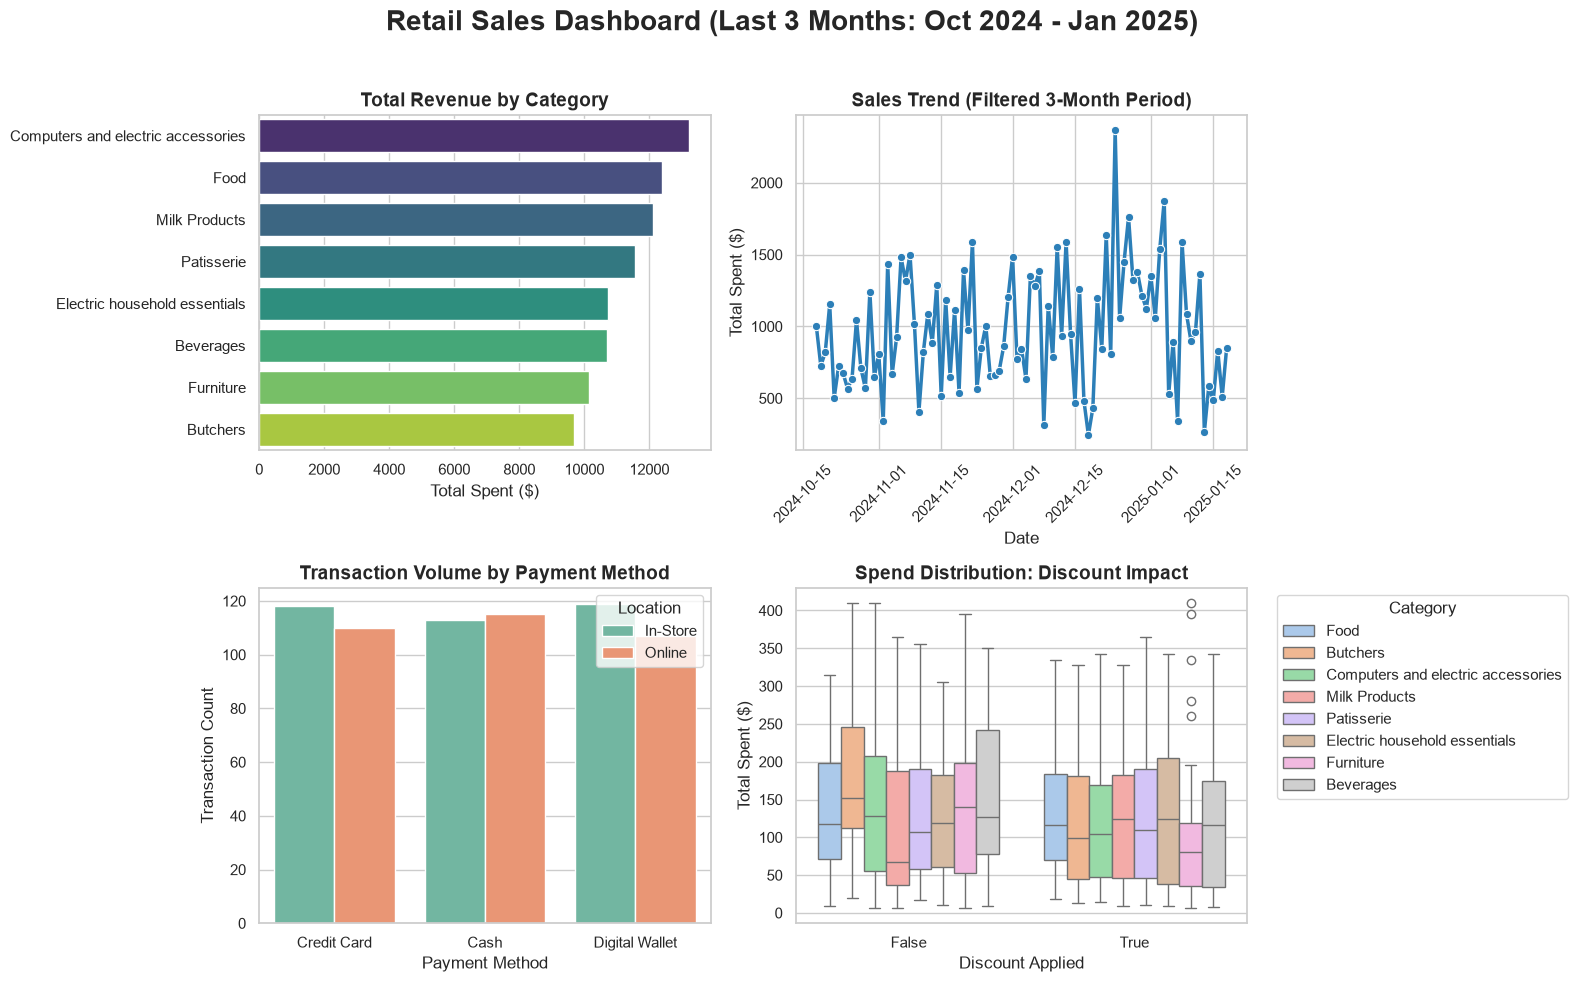

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.dates import DateFormatter

# 1. Load & Filter Data
df = pd.read_csv('cleaned_retail_store_sales.csv')
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])

# Apply 6-month lookback filter
latest_date = df['Transaction Date'].max()
cutoff_date = latest_date - pd.DateOffset(months=3)
df_filtered = df[df['Transaction Date'] >= cutoff_date].sort_values('Transaction Date')

# 2. Dashboard Setup
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    f"Retail Sales Dashboard (Last 3 Months: {cutoff_date.strftime('%b %Y')} - {latest_date.strftime('%b %Y')})", 
    fontsize=20, fontweight='bold', y=0.98
)

# --- PLOT 1: Revenue by Category ---
category_sales = df_filtered.groupby('Category')['Total Spent'].sum().reset_index().sort_values('Total Spent', ascending=False)
sns.barplot(data=category_sales, x='Total Spent', y='Category', ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title('Total Revenue by Category', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Total Spent ($)', fontsize=12)
axes[0, 0].set_ylabel('')

# --- PLOT 2: Sales Trend Over Time ---
time_sales = df_filtered.groupby('Transaction Date')['Total Spent'].sum().reset_index()
sns.lineplot(data=time_sales, x='Transaction Date', y='Total Spent', ax=axes[0, 1], marker='o', linewidth=2.5, color="#2c7fb8")
axes[0, 1].set_title('Sales Trend (Filtered 3-Month Period)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Date', fontsize=12)
axes[0, 1].set_ylabel('Total Spent ($)', fontsize=12)
axes[0, 1].xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
axes[0, 1].tick_params(axis='x', rotation=45)

# --- PLOT 3: Payment Method vs Location ---
sns.countplot(data=df_filtered, x='Payment Method', hue='Location', ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title('Transaction Volume by Payment Method', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Payment Method', fontsize=12)
axes[1, 0].set_ylabel('Transaction Count', fontsize=12)

# --- PLOT 4: Discount Impact ---
sns.boxplot(data=df_filtered, x='Discount Applied', y='Total Spent', hue='Category', ax=axes[1, 1], palette="pastel")
axes[1, 1].set_title('Spend Distribution: Discount Impact', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Discount Applied', fontsize=12)
axes[1, 1].set_ylabel('Total Spent ($)', fontsize=12)
axes[1, 1].legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()